# 04 · Replay della coda su Nasdaq ITCH (esperimento E3, risultato principale)

**Domanda di ricerca.** Quanto cambia la valutazione di una strategia di market making passivo quando le esecuzioni stimate con regole L2 vengono confrontate con un replay order-level che considera la posizione nella coda?

È il **notebook centrale** della tesi: con i dati ITCH si sa quanto volume c'è davanti alla quota, quindi l'esecuzione si può simulare rigiocando il flusso storico (coda FIFO, priorità prezzo-tempo).

**Esempio.** Al prezzo di 100 USD sono in attesa 500 azioni. La quota virtuale di 100 azioni entra **dopo** quelle 500.

* Se alcune delle 500 azioni vengono **cancellate**, la coda davanti si accorcia ma la quota **non** viene eseguita.
* Se vengono **eseguite** 300 azioni, la coda davanti scende a 200: la quota non è ancora raggiunta.
* La quota viene eseguita solo quando un'esecuzione arriva fino alla sua posizione, anche solo in parte.

Diversamente dai modelli stocastici della coda (Cont, Stoikov e Talreja, 2010; Huang, Lehalle e Rosenbaum, 2015), qui la coda non è simulata da una distribuzione: si rigioca il flusso reale. Moallemi e Yuan (2017) mostrano che la posizione in coda ha un valore economico: stare in fondo significa essere eseguiti soprattutto quando il livello si sta svuotando, cioè quando il prezzo sta per muoversi.

**Dati:** calibrazione 30/01/2019, validazione 27/03/2019, test **5 giornate × 3 titoli = 15 titolo-giorni** (luglio 2019 - gennaio 2020, 09:30-16:00), 100 azioni per lato. Le regole L2 sono simulate sulla vista L2 dello stesso flusso.

**Costi.** Le tariffe usate (Nasdaq: rebate di 0,20 cent/azione al maker, 0,30 cent/azione al taker; Hyperliquid: 1,5 bps maker e 4,5 bps taker al livello base, −0,3 e 2,4 bps al livello alto) sono **ipotesi sperimentali indicative**, da verificare sulle tabelle ufficiali del periodo analizzato.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti esplorative
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

def bias_figure(name, stats, unit, filename):
    """P&L per regola e rapporto tra esecuzioni L2 ed esecuzioni con la coda."""
    bias = R.fill_bias(test, name).median()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio (IC 95% per sessione)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    axes[1].bar([R.LABELS[m] for m in bias.index], bias, color=[R.COLORS[m] for m in bias.index], width=0.6)
    for k, v in enumerate(bias):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Esecuzioni L2 / esecuzioni con la coda (mediana)", ylabel="Rapporto", ylim=(0.5, bias.max() * 3))
    axes[1].grid(axis="x", visible=False)
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches="tight")
    plt.show()
    return bias


def same_session_table(name, session, symbol, fee, net):
    """Tutte le metriche di una singola sessione, stessi parametri, quattro modelli."""
    from market_making_tesi.evaluation import order_fill_rate
    rows = test[(test.dataset == name) & (test.session == session) & (test.symbol == symbol)].set_index("model")
    rows = rows.loc[[m for m in R.MODEL_ORDER if m in rows.index]]
    queue_fills = rows.loc["queue", "maker_fills"]
    table = pd.DataFrame({
        "esecuzioni maker": rows.maker_fills.map(lambda v: it(v)),
        "rapporto con la coda": (rows.maker_fills / queue_fills).map(lambda v: f"{it(v, 1)}×"),
        "quote eseguite": order_fill_rate(rows).map(lambda v: pct(v, 1)),
        "turnover (USD)": rows.turnover.map(lambda v: it(v)),
        "P&L lordo": rows.final_equity.map(lambda v: it(v, 2)),
        "commissioni": (-rows[fee]).map(lambda v: it(v, 2)),
        "P&L netto": rows[net].map(lambda v: it(v, 2)),
        "edge maker": rows.maker_edge.map(lambda v: it(v, 2)),
        "costo liquidazioni": rows.liquidation_cost.map(lambda v: it(v, 2)),
        "P&L di inventario": rows.inventory_pnl.map(lambda v: it(v, 2)),
        "markout": rows.adverse_selection.map(lambda v: it(v, 2)),
        "inventario massimo": rows.max_abs_inventory_seen.map(lambda v: it(v, 2)),
        "rifiuti post-only": rows.post_only_rejects.map(lambda v: it(v)),
    })
    table.index = [R.LABELS[m] for m in table.index]
    return table.T

stats = R.model_table_grouped(test, "itch", "final_equity")
queue = test[(test.dataset == "itch") & (test.model == "queue")]
from market_making_tesi.evaluation import grouped_bootstrap_ci
mean, low, high = grouped_bootstrap_ci(queue.net_nasdaq_base, queue.session)
R.show_box("In breve", [
    f"Con la coda reale la strategia ha un P&L netto medio di {it(mean, 2)} USD per titolo-giorno (IC 95% per giornata {it(low, 2)}; {it(high, 2)}), negativo in {it((queue.net_nasdaq_base < 0).sum())} titolo-giorni su {len(queue)}.",
    f"Con `touch`, sugli stessi dati, il P&L lordo sarebbe di {it(stats.loc['touch', 'media'], 2)} USD per titolo-giorno: è un limite superiore ottimistico.",
    "La perdita viene soprattutto dalla selezione avversa: le quote vengono eseguite quando il prezzo sta per muoversi contro.",
])

> **In breve**
>
> - Con la coda reale la strategia ha un P&L netto medio di -540,59 USD per titolo-giorno (IC 95% per giornata -580,70; -500,47), negativo in 15 titolo-giorni su 15.
> - Con `touch`, sugli stessi dati, il P&L lordo sarebbe di 112.107,93 USD per titolo-giorno: è un limite superiore ottimistico.
> - La perdita viene soprattutto dalla selezione avversa: le quote vengono eseguite quando il prezzo sta per muoversi contro.

## 1. Scelta dei parametri (validazione)

P&L netto medio sulla giornata di validazione per le 12 combinazioni, con la coda FIFO; più scuro = migliore. Con **una sola giornata di validazione** la scelta può adattarsi al caso: la griglia completa serve da analisi di sensibilità.

In [2]:
display(R.validation_grid(validation, "itch", "net_nasdaq_base").style.format("{:.2f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('itch', selected['itch']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 120 secondi; si opera solo sotto il 50° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 30 s.

## 2. Una sessione, quattro modelli

AAPL il 30/07/2019, con gli stessi parametri. Tutte le grandezze sono in USD tranne i conteggi; le commissioni sono positive quando sono un costo.

In [3]:
display(same_session_table("itch", "2019-07-30", "AAPL", "fees_nasdaq_base", "net_nasdaq_base"))
display(Markdown(
    "**Come leggerlo.** Un numero di esecuzioni più basso non rende un modello peggiore: la coda FIFO esegue la quota "
    "solo quando gli scambi arrivano davvero fino a lei, e per questo produce una stima più credibile, anche se meno "
    "favorevole. Il *markout* negativo indica che dopo le esecuzioni il prezzo si è mosso contro la posizione."))

,touch,price-through,cross,coda FIFO
esecuzioni maker,112.366,1.878,1.725,1.562
rapporto con la coda,"71,9×","1,2×","1,1×","1,0×"
quote eseguite,"99,6%","78,4%","76,2%","57,6%"
turnover (USD),2.351.507.403,49.838.901,47.045.528,26.944.300
P&L lordo,"101.435,00","-1.145,00","-1.920,00","-614,38"
commissioni,"22.350,80","222,00","185,70","72,35"
P&L netto,"123.785,80","-923,00","-1.734,30","-542,03"
edge maker,"102.305,50","184,50","-990,00","559,39"
costo liquidazioni,"-296,00","-381,00","-400,50","-270,44"
P&L di inventario,"-574,50","-948,50","-529,50","-903,33"


**Come leggerlo.** Un numero di esecuzioni più basso non rende un modello peggiore: la coda FIFO esegue la quota solo quando gli scambi arrivano davvero fino a lei, e per questo produce una stima più credibile, anche se meno favorevole. Il *markout* negativo indica che dopo le esecuzioni il prezzo si è mosso contro la posizione.

## 3. Tutte le sessioni di test

**Intervalli di confidenza.** I titoli della stessa giornata non sono osservazioni indipendenti: l'intervallo principale ricampiona **giornate (o ore) intere** con tutti i loro titoli (bootstrap per sessione, seme fisso). Con poche sessioni indipendenti (5 giornate ITCH, 4 ore Hyperliquid) anche questo intervallo è un'approssimazione e può sottostimare l'incertezza.

,giornate indipendenti,titolo-sessioni,P&L netto medio (IC 95% per sessione),IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,5,15,"139.086,43 (131.220,13; 145.444,17)","(121.853,75; 158.196,63)",100%,"99,7%",1.663.163.114
price-through,5,15,"-392,79 (-663,31; 29,01)","(-672,33; 81,29)",7%,"68,3%",34.547.647
cross,5,15,"-1.305,11 (-1.525,02; -1.085,21)","(-1.814,21; -876,74)",0%,"66,6%",28.420.777
coda FIFO,5,15,"-540,59 (-580,70; -500,47)","(-659,64; -434,79)",0%,"49,7%",15.837.570


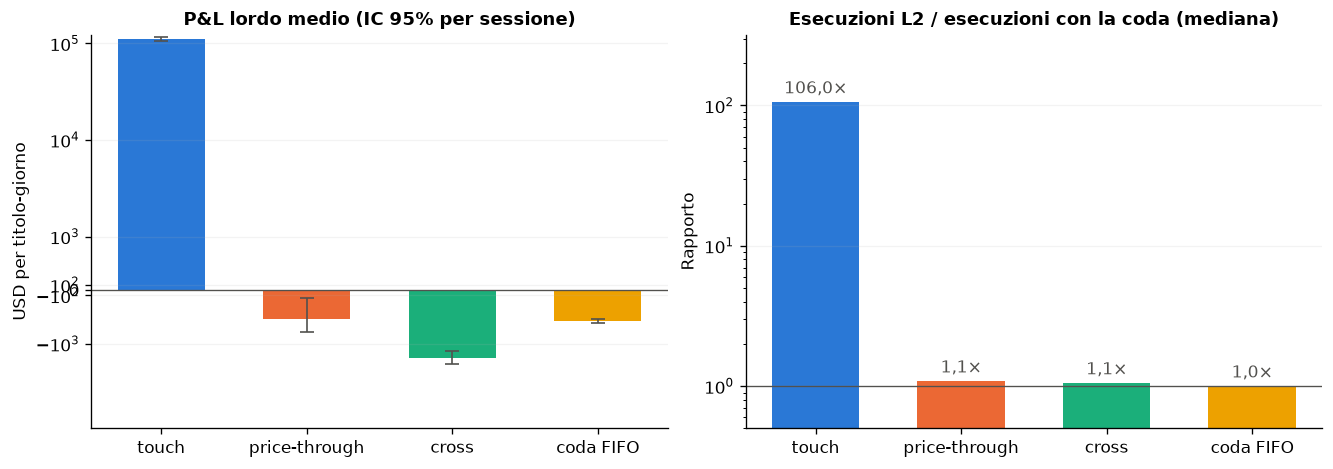

*Figura.* P&L lordo medio per modello (sinistra, scala simmetrica logaritmica) e rapporto tra le esecuzioni di ogni regola e quelle della coda (destra). `touch` conta 106 volte le esecuzioni della coda e trasforma una perdita in un guadagno; `price-through` e `cross` sono vicine nel numero di esecuzioni (1,1× e 1,1×) ma non nel P&L. *Limite:* cinque giornate di test non bastano per una stima precisa del P&L medio.

In [4]:
display(R.overview_table(test, "itch", "net_nasdaq_base", 2))
bias = bias_figure("itch", stats, "USD per titolo-giorno", "itch_test.png")
R.caption("P&L lordo medio per modello (sinistra, scala simmetrica logaritmica) e rapporto tra le esecuzioni di ogni regola e quelle della coda (destra).",
          f"`touch` conta {it(bias['touch'])} volte le esecuzioni della coda e trasforma una perdita in un guadagno; "
          f"`price-through` e `cross` sono vicine nel numero di esecuzioni ({it(bias['price-through'], 1)}× e {it(bias['cross'], 1)}×) ma non nel P&L.",
          "cinque giornate di test non bastano per una stima precisa del P&L medio.")

## 4. Perché la strategia perde

Scomposizione media per titolo-giorno (USD): spread incassato rispetto al midpoint, costo per chiudere a mercato le coppie rimaste a metà, movimento del prezzo sull'inventario, commissioni.

In [5]:
dec = R.decomposition(test, "itch", "fees_nasdaq_base")
display(R.decomposition_table(dec, 2))
display(R.fill_rates_table(R.fill_rates(test, "itch")))
d = dec.loc["coda FIFO"]
display(Markdown(
    f"**Come leggerlo.** Con la coda reale la strategia incassa {it(d['maker_edge'], 2)} USD di spread per titolo-giorno, ma "
    f"perde {it(-d['inventory_pnl'], 2)} USD perché dopo un'esecuzione il prezzo tende a muoversi contro la posizione "
    f"(**selezione avversa**, Glosten e Milgrom, 1985) e {it(-d['liquidation_cost'], 2)} USD per chiudere a mercato le "
    "coppie rimaste a metà."))
display(Markdown("**P&L netto per giornata e titolo (coda FIFO, USD)**"))
display(queue.pivot_table(index="session", columns="symbol", values="net_nasdaq_base").round(2))

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
touch,"112.494,37","-288,20","-98,23","112.107,93","26.978,49","139.086,43"
price-through,"477,97","-367,83","-643,73","-533,60","140,81","-392,79"
cross,"-839,83","-382,87","-178,23","-1.400,93","95,82","-1.305,11"
coda FIFO,"437,02","-268,61","-738,69","-570,29","29,70","-540,59"


,coppie quotate,entrambi i lati eseguiti,un solo lato eseguito,nessun lato eseguito,con fill parziale
touch,1.018.516,99%,1%,0%,0%
price-through,14.747,48%,48%,4%,0%
cross,13.180,41%,54%,5%,0%
coda FIFO,10.990,26%,48%,26%,12%


**Come leggerlo.** Con la coda reale la strategia incassa 437,02 USD di spread per titolo-giorno, ma perde 738,69 USD perché dopo un'esecuzione il prezzo tende a muoversi contro la posizione (**selezione avversa**, Glosten e Milgrom, 1985) e 268,61 USD per chiudere a mercato le coppie rimaste a metà.

**P&L netto per giornata e titolo (coda FIFO, USD)**

symbol,AAPL,INTC,MSFT
session,,,
2019-07-30,-542.03,-354.60,-533.88
2019-08-30,-922.98,-368.14,-344.90
2019-10-30,-966.93,-379.63,-404.55
2019-12-30,-898.09,-343.31,-544.76
2020-01-30,-762.03,-401.22,-341.75


## 5. Il filtro di volatilità

Su ITCH la volatilità è misurata **in secondi** (midpoint campionato ogni secondo): misurarla per messaggio darebbe stime falsate all'apertura, quando migliaia di messaggi non muovono il prezzo.

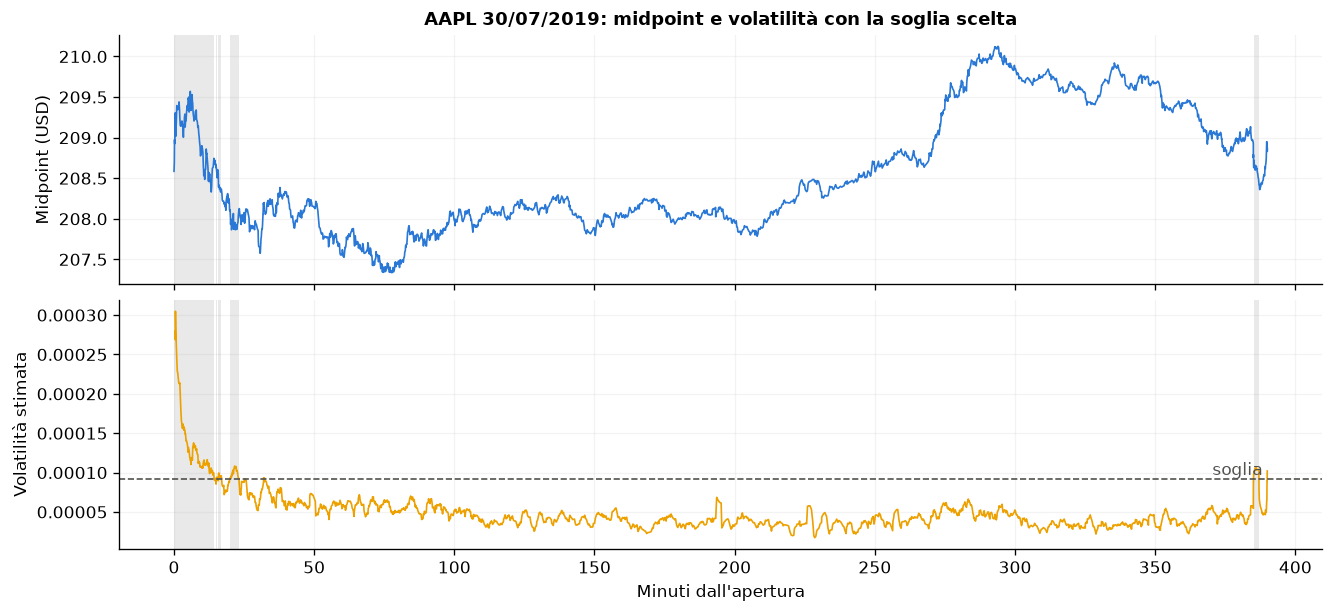

*Figura.* Midpoint (sopra) e volatilità stimata (sotto); in grigio i periodi in cui la strategia è ferma. La strategia opera nell'89% della sessione e si ferma soprattutto dopo l'apertura e nei picchi di volatilità. *Limite:* la soglia viene da una sola giornata di calibrazione, che può avere un livello di volatilità diverso dalle giornate di test.

**Con filtro e sempre attiva** (P&L netto per titolo-giorno, USD)

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,"139.086,43","171.576,43","-32.490,01 (-49.379,74; -17.391,77)",0%,71%
price-through,"-392,79","-412,89","20,10 (-120,67; 111,39)",73%,71%
cross,"-1.305,11","-1.786,25","481,14 (280,55; 846,09)",100%,71%
coda FIFO,"-540,59","-691,75","151,17 (61,79; 295,65)",80%,71%


In [6]:
row = queue[(queue.session == "2019-07-30") & (queue.symbol == "AAPL")].iloc[0]
equity = pd.read_csv(ROOT / "results/runs/itch/2019-07-30_AAPL/queue/equity.csv")
minutes = (equity.timestamp - 34_200 * 10**9) / 6e10
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
R.plot_regime(axes, equity, row.volatility_threshold, minutes, None, "Minuti dall'apertura")
axes[0].set_ylabel("Midpoint (USD)")
axes[0].set_title("AAPL 30/07/2019: midpoint e volatilità con la soglia scelta")
fig.savefig(FIGURES / "itch_regime_volatilita.png", dpi=180, bbox_inches="tight")
plt.show()
R.caption("Midpoint (sopra) e volatilità stimata (sotto); in grigio i periodi in cui la strategia è ferma.",
          f"La strategia opera {R.nel(row.active_share, 0)} della sessione e si ferma soprattutto dopo l'apertura e nei picchi di volatilità.",
          "la soglia viene da una sola giornata di calibrazione, che può avere un livello di volatilità diverso dalle giornate di test.")
display(Markdown("**Con filtro e sempre attiva** (P&L netto per titolo-giorno, USD)"))
display(R.filter_table(R.filter_effect(test, ablation, "itch", "net_nasdaq_base"), 2))

## 6. Varianti esplorative

Due estensioni **esplorative**, aggiunte dopo aver osservato le perdite della strategia base e valutate sulle stesse sessioni con gli stessi parametri base:

* **inventory skew**: dopo un'esecuzione su un solo lato lascia un ordine passivo solo sul lato che riduce la posizione, invece di chiudere a mercato. Riprende lo spostamento delle quote con l'inventario di Avellaneda e Stoikov (2008), senza implementarne il modello;
* **filtro di imbalance**: quota solo con il book bilanciato e cancella una quota quando lo squilibrio dei volumi indica che il prezzo sta per attraversarla (Cont, Kukanov e Stoikov, 2014; Cartea, Donnelly e Jaimungal, 2018).

In [7]:
display(R.variants_table(R.variant_effect(test, variants, "itch", "net_nasdaq_base", fee_column="fees_nasdaq_base"), 2))
for variant, info in selected["variants"]["itch"].items():
    display(Markdown(f"- **{R.VARIANT_LABELS[variant]}:** {R.params_text('itch', info['params'])}"))

,P&L netto medio (IC 95%),sessioni positive,differenza vs base (IC 95%),liquidazioni a mercato per sessione
variante,,,,
base,"-540,59 (-580,70; -500,47)",0%,—,392
inventory skew,"-144,48 (-238,66; -69,19)",13%,"396,10 (290,07; 475,96)",29
filtro di imbalance,"-259,19 (-296,80; -207,90)",0%,"281,39 (243,09; 319,69)",524
skew + imbalance,"-70,75 (-121,00; -23,00)",13%,"469,84 (426,94; 530,93)",25


- **filtro di imbalance:** si quota solo con imbalance |I| ≤ 0,3

- **inventory skew:** inventario smaltito con quote passive migliorate di 1 tick, liquidazione a mercato solo dopo 10 volte la durata di una quota

- **skew + imbalance:** inventario smaltito con quote passive al miglior prezzo corrente, liquidazione a mercato solo dopo 10 volte la durata di una quota; si quota solo con imbalance |I| ≤ 0,3